# Module 08: Gold Mart Assembly & Logistics Analytics


### 1. Loading Cleaned Data from the Silver Layer

We start by importing the necessary libraries and loading our core cleaned datasets (`orders`, `order_items`, `customers`, `sellers`, `products`, and `geolocation`) from the Silver layer.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets from the Silver layer
orders = pd.read_parquet('../data/orders_clean.parquet')
order_items = pd.read_parquet('../data/order_items_clean.parquet')
customers = pd.read_parquet('../data/customers_clean.parquet')
sellers = pd.read_parquet('../data/sellers_clean.parquet')
products = pd.read_parquet('../data/products_clean.parquet')
geolocation = pd.read_parquet('../data/geolocation_clean.parquet')

# Sanity check: verify dataset shapes
print(f"Orders shape: {orders.shape}")
print(f"Order Items shape: {order_items.shape}")
print(f"Customers shape: {customers.shape}")
print(f"Sellers shape: {sellers.shape}")

Orders shape: (97961, 9)
Order Items shape: (112646, 7)
Customers shape: (99441, 5)
Sellers shape: (3095, 4)


### 2. Building the Gold Master Mart & Spatial Calculations

To analyze logistics, we need to map geographic coordinates and calculate distances:
1. **Geolocation Aggregation**: Group `geolocation` by zip code prefix to eliminate coordinate duplicates, taking the mean latitude/longitude and modal city/state.
2. **Spatial Join**: Attach coordinates to both customers and sellers.
3. **Haversine Distance**: Calculate the physical delivery distance (in km) between the seller and customer for each order item.
4. **Master Mart Merge**: Combine items, orders, customers, sellers, and products into a single analytical table.

In [10]:
# Helper Functions 
def get_safe_mode(series):
    """Safely retrieve the most frequent value without failing on empty series."""
    m = series.mode()
    return m.iloc[0] if not m.empty else None

def calculate_haversine(lat1, lon1, lat2, lon2):
    """Calculate the great-circle distance between two points on the Earth (in km)."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371 * c


# Geolocation Aggregation & Spatial Preparation 
dim_geo = (
    geolocation.groupby('geolocation_zip_code_prefix')
    .agg(
        lat=('geolocation_lat', 'mean'),
        lng=('geolocation_lng', 'mean'),
        city=('geolocation_city', get_safe_mode),
        state=('geolocation_state', get_safe_mode)
    )
    .reset_index()
)

cust_geo = (
    customers
    .merge(dim_geo, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
    .rename(columns={'lat': 'customer_lat', 'lng': 'customer_lng'})
)

sell_geo = (
    sellers
    .merge(dim_geo, left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
    .rename(columns={'lat': 'seller_lat', 'lng': 'seller_lng'})
)


# 3. Master Mart Assembly via Method Chaining 
master_df = (
    order_items
    .merge(orders, on='order_id', how='inner')
    .merge(cust_geo[['customer_id', 'customer_state', 'customer_lat', 'customer_lng']], on='customer_id', how='left')
    .merge(sell_geo[['seller_id', 'seller_state', 'seller_lat', 'seller_lng']], on='seller_id', how='left')
    .merge(products, on='product_id', how='left')
)


# 4. Haversine Distance Calculation 
valid_geo = master_df['seller_lat'].notna() & master_df['customer_lat'].notna()
master_df['distance_km'] = np.nan
master_df.loc[valid_geo, 'distance_km'] = calculate_haversine(
    master_df.loc[valid_geo, 'seller_lat'], master_df.loc[valid_geo, 'seller_lng'],
    master_df.loc[valid_geo, 'customer_lat'], master_df.loc[valid_geo, 'customer_lng']
).round(2)


# 5. Sanity Check
display(master_df[['order_id', 'seller_state', 'customer_state', 'distance_km', 'price']].head())
print(f"Master Mart total rows: {len(master_df):,}")

,order_id,seller_state,customer_state,distance_km,price
0,00010242fe8c5a6d1ba2dd792cb16214,SP,RJ,301.42,58.90
1,00018f77f2f0320c557190d7a144bdd3,SP,SP,585.07,239.90
2,000229ec398224ef6ca0657da4fc703e,MG,MG,312.39,199.00
3,00024acbcdf0a6daa1e931b038114c75,SP,SP,295.48,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,PR,SP,646.15,199.90


Master Mart total rows: 110,945


### 3. Feature Engineering and Defensive Filtering (Guardrails)

Now we derive analytical metrics and apply strict guardrails to ensure data integrity:
* **Temporal Metrics**: Calculate `seller_handling_days`, `carrier_transit_days`, and `delivery_error_days`.
* **Counter-Metric**: Track `estimated_transit_days` to ensure we aren't artificially inflating delivery estimates and hurting conversion.
* **Risk Flags**: Create `is_underestimated` (delayed orders) and financial exposure (`gmv_underestimated`).
* **Guardrails**: Filter for delivered orders with valid timestamps and remove geographic outliers (Brazil maximum span is ~4,300 km).

In [12]:
# Convert date columns to datetime
date_cols = [
    'order_purchase_timestamp', 'order_approved_at', 
    'order_delivered_carrier_date', 'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]
for col in date_cols:
    master_df[col] = pd.to_datetime(master_df[col])

# Calculate delivery deltas
master_df['seller_handling_days'] = (master_df['order_delivered_carrier_date'] - master_df['order_approved_at']).dt.days
master_df['carrier_transit_days'] = (master_df['order_delivered_customer_date'] - master_df['order_delivered_carrier_date']).dt.days
master_df['delivery_error_days'] = (master_df['order_delivered_customer_date'] - master_df['order_estimated_delivery_date']).dt.days
master_df['estimated_transit_days'] = (master_df['order_estimated_delivery_date'] - master_df['order_purchase_timestamp']).dt.days

# Risk indicators
master_df['is_underestimated'] = (master_df['delivery_error_days'] > 0).astype(int)
master_df['abs_error_days'] = master_df['delivery_error_days'].abs()
master_df['gmv_underestimated'] = master_df['price'] * master_df['is_underestimated']

# Apply Guardrails
clean_df = master_df[
    (master_df['order_status'] == 'delivered') &
    (master_df['order_delivered_customer_date'].notna()) &
    (master_df['order_estimated_delivery_date'].notna()) &
    (master_df['order_approved_at'].notna()) &
    (master_df['order_delivered_carrier_date'].notna()) &
    (master_df['distance_km'].notna()) &
    (master_df['distance_km'].between(1, 4300))
].copy()

print(f"Rows before filtering: {len(master_df):,}")
print(f"Rows after applying Guardrails: {len(clean_df):,}")

Rows before filtering: 110,945
Rows after applying Guardrails: 107,895


### 4. Hypothesis 1: Macro Distance Impact & Counter-Metrics

#### Evaluating Distance Decay on Delivery Performance
Grouping orders into distance tiers (Local to Remote) to test whether physical distance drives delivery delays, while tracking the counter-metric (`avg_estimated_days`) to ensure forecast buffers scale reasonably.

In [13]:
bins = [-np.inf, 200, 500, 1000, np.inf]
labels = ['1. Local (< 200 km)', '2. Regional (200-500 km)', '3. National (500-1000 km)', '4. Remote / Glush (> 1000 km)']
clean_df['distance_bucket'] = pd.cut(clean_df['distance_km'], bins=bins, labels=labels)

distance_report = clean_df.groupby('distance_bucket', observed=False).agg(
    unique_orders=('order_id', 'nunique'),
    underestimated_pct=('is_underestimated', lambda x: round(100.0 * x.mean(), 2)),
    avg_estimated_days=('estimated_transit_days', lambda x: round(x.mean(), 2)), # Counter-metric
    mae_days=('abs_error_days', lambda x: round(x.mean(), 2)),
    median_error_days=('delivery_error_days', lambda x: round(x.quantile(0.5), 2)),
    p90_error_days=('delivery_error_days', lambda x: round(x.quantile(0.9), 2))
).reset_index()

display(distance_report)

,distance_bucket,unique_orders,underestimated_pct,avg_estimated_days,mae_days,median_error_days,p90_error_days
0,1. Local (< 200 km),24316,4.62,16.13,10.68,-10.0,-2.0
1,2. Regional (200-500 km),30011,6.14,23.42,13.73,-13.0,-3.0
2,3. National (500-1000 km),25500,7.05,26.02,14.30,-14.0,-2.0
3,4. Remote / Glush (> 1000 km),15159,10.34,31.00,15.45,-14.0,1.0


### 5. Hypothesis 2: Micro-Analysis of Problematic Sellers

#### Identifying Operational Bottlenecks & Financial Risk
Auditing individual vendors to isolate chronic underperformers (delay rate > 15%) and mapping their handling time against financial exposure (`gmv_at_risk`) to guide management actions.

In [14]:
seller_stats = clean_df.groupby('seller_id').agg(
    total_items=('order_item_id', 'count'),
    underestimated_pct=('is_underestimated', lambda x: round(100.0 * x.mean(), 2)),
    avg_handling_days=('seller_handling_days', lambda x: round(x.mean(), 2)),
    gmv_at_risk=('gmv_underestimated', 'sum')
).reset_index()

top_bad_sellers = seller_stats[
    (seller_stats['total_items'] >= 30) & 
    (seller_stats['underestimated_pct'] > 15)
].sort_values(by='gmv_at_risk', ascending=False)

display(top_bad_sellers.head(10))

,seller_id,total_items,underestimated_pct,avg_handling_days,gmv_at_risk
1323,712e6ed8aa4aa1fa65dab41fed5737e4,84,20.24,6.55,8669.00
79,06a2c3af7b3aee5d69171b0e14f0ee87,381,20.21,4.25,6497.23
1591,88460e8ebdecbfecb5f9601833981930,296,16.22,7.45,6054.65
2701,ea566164622c6b439516ab18062c42cd,50,20.00,3.14,4619.70
2385,cd68562d3f44870c08922d380acae552,129,17.83,2.96,3942.00
989,54965bbe3e4f07ae045b90b0b8541f52,79,32.91,15.57,3362.70
1128,6039e27294dc75811c0d8a39069f52c0,74,21.62,5.86,3358.40
1982,abe42c5d03695b4257b5c6cbf4e6784e,48,16.67,1.17,2722.00
1196,66e0557ecc2b4dbea057e93f215f68d8,30,20.00,17.50,2274.00
2283,c60b801f2d52c7f7f91de00870882a75,39,15.38,6.41,2160.00


#### Root Cause Analysis: Handling Time vs. Delay Rate
Mapping vendor handling duration against delivery error percentages, weighted by financial exposure (GMV at risk), to differentiate operational bottlenecks from systemic logistics issues.

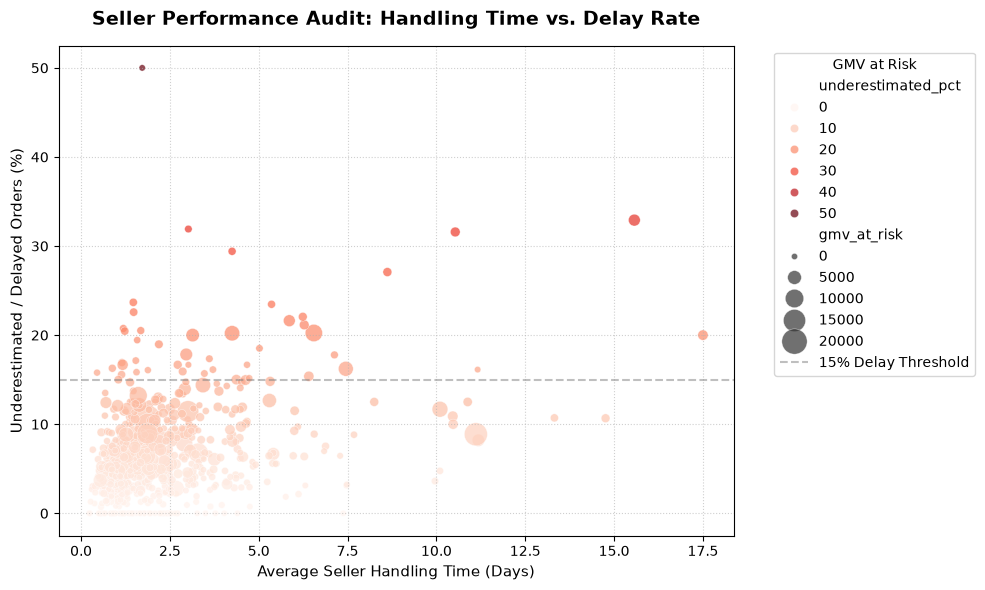

In [16]:
plot_data = seller_stats[seller_stats['total_items'] >= 30].copy()

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_data,
    x='avg_handling_days',
    y='underestimated_pct',
    size='gmv_at_risk',
    sizes=(20, 400),
    hue='underestimated_pct',
    palette='Reds',
    alpha=0.7
)

plt.title('Seller Performance Audit: Handling Time vs. Delay Rate', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Seller Handling Time (Days)', fontsize=11)
plt.ylabel('Underestimated / Delayed Orders (%)', fontsize=11)
plt.axhline(15, color='gray', linestyle='--', alpha=0.5, label='15% Delay Threshold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='GMV at Risk')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 6. Hypothesis 3: Product Category Bottlenecks

#### Evaluating Category-Specific Vulnerabilities
Aggregating delivery metrics by product category (filtering for categories with a statistically significant volume of at least 100 items) to identify which types of goods drive the highest delay rates and carrier transit bottlenecks.

In [17]:
# Grouping data by product category and calculating delivery KPIs
cat_stats = clean_df.groupby('product_category_name').agg(
    total_items=('order_item_id', 'count'),
    underestimated_pct=('is_underestimated', lambda x: round(100.0 * x.mean(), 2)),
    avg_carrier_transit=('carrier_transit_days', lambda x: round(x.mean(), 2)),
    avg_handling=('seller_handling_days', lambda x: round(x.mean(), 2))
).reset_index()

# Filter for categories with sample size >= 100 and sort by highest delay rate
top_bad_categories = (
    cat_stats[cat_stats['total_items'] >= 100]
    .sort_values(by='underestimated_pct', ascending=False)
)

# Display the top 10 most problematic categories
display(top_bad_categories.head(10))

,product_category_name,total_items,underestimated_pct,avg_carrier_transit,avg_handling
7,audio,355,11.83,9.97,2.10
6,artigos_de_natal,149,10.07,12.00,2.39
14,casa_conforto,421,9.50,10.35,1.92
39,fashion_underwear_e_moda_praia,127,9.45,8.98,3.45
49,livros_tecnicos,254,8.27,7.39,2.06
55,moveis_escritorio,1639,8.05,9.58,9.84
9,bebes,2930,7.75,8.77,2.44
11,beleza_saude,9257,7.66,8.46,2.22
72,unknown,1517,7.58,8.63,2.79
45,instrumentos_musicais,640,7.50,9.20,2.41


### 8. Executive Summary & Strategic Recommendations

Our end-to-end logistics audit of the Olist dataset reveals that delivery failures and churn are driven by specific operational bottlenecks rather than random variance. Addressing these issues directly reduces support complaint costs, financial compensation payouts, and customer attrition.

#### Key Findings & Root Causes:
1. **Macro-Level (Distance & Over-Buffering vs. Conversion Loss):** 
   * Delay rates predictably scale with distance (from **4.6%** locally to **10.3%** in remote regions). However, the platform suffers from **severe systemic over-buffering**: median deliveries arrive **10 to 14 days earlier** than promised. This artificial inflation of delivery windows severely damages checkout conversion rates (our primary **Counter-Metric** risk).
2. **Micro-Level (Vendor Bottlenecks vs. Courier Failures):** 
   * Scatter analysis of financial exposure (`gmv_at_risk`) isolates chronic underperformers into two distinct groups:
     * **Vendor Bottlenecks ("Slowpokes"):** Merchants taking 7–17+ days just to pack orders.
     * **Courier Failures:** Merchants with fast dispatch times (< 3 days) whose items still arrive late due to regional last-mile failures.
3. **Category-Specific Constraints:** 
   * Vulnerabilities are localized: **Audio/Electronics** suffer from transit bottlenecks, **Christmas goods** hit seasonal network congestion, and **Furniture** causes internal seller handling delays due to packaging complexity.

#### Immediate Actionable Recommendations (1–2 Week Implementation):
* **Algorithmic Forecast Recalibration (Website Engine):** Aggressively trim estimated delivery buffers by 5–7 days for Local and Regional zones. This instantly recovers dropped checkout conversions while maintaining safe target error rates (`underestimated_pct`).
* **Differentiated Merchant Policy (SLA Enforcement & Demotions):** 
  * Apply **search ranking demotions** and **operational fines** specifically to vendors with high handling times (Cluster 1). 
  * **Protect fast-dispatch vendors (Cluster 2)** from unfair penalties, redirecting operational focus to carrier accountability.
* **Regional Carrier Restructuring:** Renegotiate contracts or re-route logistics streams in remote and high-delay states to reduce late-delivery compensation payouts and customer support overhead.